In [2]:
import os, subprocess
from google.colab import userdata
tok = userdata.get("GH_TOKEN")
def clone(url, dest):
    if os.path.isdir(dest):
        print(dest, "already there"); return
    r = subprocess.run(["git", "clone", "-q", url, dest], capture_output=True, text=True)
    print(dest, "return code:", r.returncode, r.stderr.replace(tok, "***"))
clone("https://github.com/MSD-IRIMAS/LITE.git", "/content/LITE")
clone(f"https://{tok}@github.com/DevRana003/lite-results-65-128.git", "/content/results_store")
for k, v in (("user.name", "colab"), ("user.email", "colab@example.com")):
    subprocess.run(["git", "config", k, v], cwd="/content/results_store")
r = subprocess.run(["git", "pull", "-q"], cwd="/content/results_store", capture_output=True, text=True)
print("pull return code:", r.returncode, r.stderr.replace(tok, "***")[-200:])
!nvidia-smi --query-gpu=name --format=csv,noheader

/content/LITE return code: 0 
/content/results_store return code: 0 
pull return code: 0 
/bin/bash: line 1: nvidia-smi: command not found


In [7]:
!pip install -q aeon codecarbon setuptools

In [8]:
import os, subprocess
os.chdir("/content/LITE")
P = "src/classifiers/lite.py"
if "LITE_EARLY_STOPPING" not in open(P).read():
    r = subprocess.run(["python", "/content/results_store/patch_lite_es.py"], capture_output=True, text=True)
    print(r.stdout, r.stderr[-500:])
s = open(P).read()
s = s.replace("n_epochs=2,", "n_epochs=1500,")
if "min_delta" not in s:
    assert s.count("patience=self.patience,") == 1, "EarlyStopping line not found"
    s = s.replace("patience=self.patience,",
                  'patience=self.patience, min_delta=float(os.environ.get("LITE_MIN_DELTA", "0")),')
if "LITE_SEED_TAG" not in s:
    old = 'seed = zlib.crc32("/".join(os.path.normpath(self.output_directory).split(os.sep)[-2:]).encode()) % (2**31 - 1)'
    new = 'seed = zlib.crc32(("/".join(os.path.normpath(self.output_directory).split(os.sep)[-2:]) + os.environ.get("LITE_SEED_TAG", "")).encode()) % (2**31 - 1)'
    assert s.count(old) == 1, "seed line not found"
    s = s.replace(old, new)
open(P, "w").write(s)
s = open(P).read()
compile(s, P, "exec")
assert "n_epochs=1500," in s and "LITE_EARLY_STOPPING" in s and s.count("min_delta") == 1 and "LITE_SEED_TAG" in s
print("lite.py ready")

lite.py ready


In [9]:
import os, subprocess, sys, time
import pandas as pd
STORE = "/content/results_store"
os.chdir("/content/LITE"); os.makedirs("/content/logs", exist_ok=True)
JOBS = [("C_es", "100"), ("D_es_p300", "300")]
DATASETS = ["Symbols", "ShapeletSim"]

def done(arm, ds, k):
    csv = f"{STORE}/results_{arm}_rep/seed{k}/LITE/results_ucr.csv"
    return os.path.exists(csv) and ds in set(pd.read_csv(csv)["dataset"])

def push(msg):
    for c in (["git", "add", "-A"], ["git", "commit", "-m", msg], ["git", "pull", "--rebase"], ["git", "push"]):
        r = subprocess.run(c, cwd=STORE, capture_output=True, text=True)
        if r.returncode != 0 and c[1] in ("pull", "push"):
            print("GIT PROBLEM:", c[1], r.stderr[-300:].replace("\n", " "), flush=True)

for arm, pat in JOBS:
    for ds in DATASETS:
        for k in range(5):
            if done(arm, ds, k):
                continue
            os.makedirs(f"{STORE}/results_{arm}_rep", exist_ok=True)
            env = dict(os.environ, LITE_EARLY_STOPPING="1", LITE_PATIENCE=pat, LITE_VAL_SPLIT="0.2",
                       LITE_MIN_DELTA="0.001", LITE_SEED_TAG=str(k))
            t1 = time.time(); log = f"/content/logs/{arm}_{ds}_{k}.log"
            with open(log, "w") as lf:
                r = subprocess.run([sys.executable, "main.py", "--dataset", ds, "--runs", "1",
                                    "--track-emissions", "True",
                                    "--output-directory", f"{STORE}/results_{arm}_rep/seed{k}/"],
                                   stdout=lf, stderr=subprocess.STDOUT, env=env)
            print(f"{arm} {ds} seed{k}: exit {r.returncode}, {(time.time() - t1) / 60:.1f} min", flush=True)
            if r.returncode != 0:
                print(open(log).read()[-800:], flush=True)
            push(f"{arm} {ds} seed{k}: exit {r.returncode}")
print("All done.", flush=True)

C_es Symbols seed0: exit 0, 1.3 min
C_es Symbols seed1: exit 0, 5.0 min
C_es Symbols seed2: exit 0, 5.5 min
C_es Symbols seed3: exit 0, 7.1 min
C_es Symbols seed4: exit 0, 5.3 min
C_es ShapeletSim seed0: exit 0, 3.8 min
C_es ShapeletSim seed1: exit 0, 1.2 min
C_es ShapeletSim seed2: exit 0, 4.9 min
C_es ShapeletSim seed3: exit 0, 1.2 min
C_es ShapeletSim seed4: exit 0, 1.5 min
D_es_p300 Symbols seed0: exit 0, 3.6 min
D_es_p300 Symbols seed1: exit 0, 6.6 min
D_es_p300 Symbols seed2: exit 0, 5.5 min
D_es_p300 Symbols seed3: exit 0, 6.1 min
D_es_p300 Symbols seed4: exit 0, 5.8 min
D_es_p300 ShapeletSim seed0: exit 0, 1.5 min
D_es_p300 ShapeletSim seed1: exit 0, 1.6 min
D_es_p300 ShapeletSim seed2: exit 0, 1.9 min
D_es_p300 ShapeletSim seed3: exit 0, 4.7 min
D_es_p300 ShapeletSim seed4: exit 0, 1.9 min
All done.


In [10]:
import glob, json, os
import pandas as pd
ST = "/content/results_store"
CHANCE = {"Symbols": 1 / 6, "ShapeletSim": 0.5}
def new(arm, ds):
    a, e = [], []
    for k in range(5):
        f = f"{ST}/results_{arm}_rep/seed{k}/LITE/results_ucr.csv"
        if os.path.exists(f):
            d = pd.read_csv(f); d = d[d["dataset"] == ds]
            if len(d): a.append(float(d["LITE-mean"].iloc[0]))
        j = glob.glob(f"{ST}/results_{arm}_rep/seed{k}/LITE/run_0/{ds}/dict_emissions.json")
        if j: e.append(json.load(open(j[0])).get("epochs_run"))
    return a, e
def orig(ds):
    a = []
    for i in range(1, 6):
        d = pd.read_csv(f"{ST}/results_pass{i}/LITE/results_ucr.csv"); d = d[d["dataset"] == ds]
        if len(d): a.append(float(d["LITE-mean"].iloc[0]))
    return a, []
for ds in CHANCE:
    print(f"\n=== {ds} (chance level {CHANCE[ds]:.3f}) ===")
    for name, (a, e) in (("A original (Kaggle)", orig(ds)), ("C patience 100", new("C_es", ds)), ("D patience 300", new("D_es_p300", ds))):
        s = pd.Series(a)
        print(f"{name:20s} n={len(a)} mean={s.mean():.3f} std={s.std():.3f} min={s.min():.3f} max={s.max():.3f} "
              f"near-chance={int((s < CHANCE[ds] + 0.05).sum())}/{len(a)}")
        print("    accuracies:", [round(x, 3) for x in a], "| epochs run:", e)


=== Symbols (chance level 0.167) ===
A original (Kaggle)  n=5 mean=0.979 std=0.002 min=0.977 max=0.981 near-chance=0/5
    accuracies: [0.98, 0.981, 0.978, 0.978, 0.977] | epochs run: []
C patience 100       n=5 mean=0.818 std=0.360 min=0.174 max=0.982 near-chance=1/5
    accuracies: [0.174, 0.98, 0.982, 0.976, 0.977] | epochs run: [129, 985, 1179, 1500, 1112]
D patience 300       n=5 mean=0.972 std=0.023 min=0.932 max=0.984 near-chance=0/5
    accuracies: [0.932, 0.983, 0.979, 0.984, 0.983] | epochs run: [859, 1500, 1115, 1500, 1500]

=== ShapeletSim (chance level 0.500) ===
A original (Kaggle)  n=5 mean=0.711 std=0.022 min=0.683 max=0.733 near-chance=0/5
    accuracies: [0.733, 0.7, 0.706, 0.683, 0.733] | epochs run: []
C patience 100       n=5 mean=0.597 std=0.134 min=0.500 max=0.772 near-chance=3/5
    accuracies: [0.711, 0.5, 0.772, 0.5, 0.5] | epochs run: [714, 123, 976, 129, 171]
D patience 300       n=5 mean=0.546 std=0.102 min=0.500 max=0.728 near-chance=4/5
    accuracies: [

In [2]:
!ls /content/results_store

datasets_65_128.txt   README.md        results_C_es_rep       results_pass3
datasets_improve.txt  reorder.py       results_D_es_p300      results_pass4
datasets_pass2.txt    results_A_base   results_D_es_p300_rep  results_pass5
failed.txt	      results_B_split  results_pass1	      run_arms.py
patch_lite_es.py      results_C_es     results_pass2	      run_shard.py


In [3]:
!test -d /content/LITE_src || cp -r /content/LITE /content/LITE_src
!ls /content/LITE_src/results.csv

/content/LITE_src/results.csv


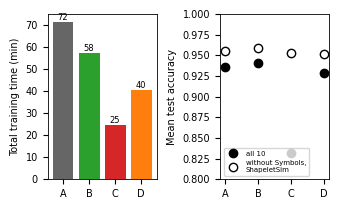

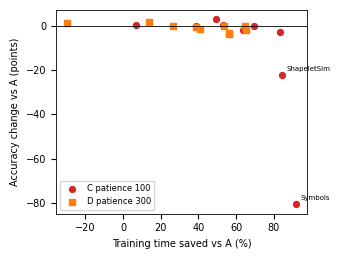

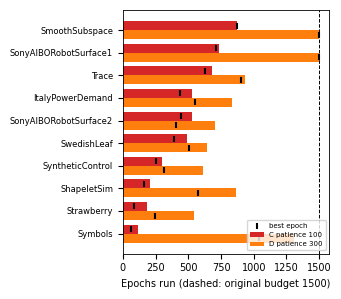

saved: totals, tradeoff, epochs


In [4]:
import glob, json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 7, "axes.linewidth": 0.6})

ST = "/content/results_store"
ARMS = ["A_base", "B_split", "C_es", "D_es_p300"]
COL = {"A_base": "0.4", "B_split": "tab:green", "C_es": "tab:red", "D_es_p300": "tab:orange"}
rows = []
for arm in ARMS:
    c = pd.read_csv(f"{ST}/results_{arm}/LITE/results_ucr.csv")
    for _, r in c.iterrows():
        f = glob.glob(f"{ST}/results_{arm}/LITE/run_0/{r['dataset']}/dict_emissions.json")
        j = json.load(open(f[0])) if f else {}
        rows.append(dict(arm=arm, ds=r["dataset"], acc=r["LITE-mean"], time=r["Training Time-mean"],
                         ep=j.get("epochs_run"), best=j.get("best_epoch")))
df = pd.DataFrame(rows)
P = lambda v: df.pivot(index="ds", columns="arm", values=v)[ARMS]
acc, tm, ep, best = P("acc"), P("time"), P("ep"), P("best")

# Figure 1: totals
x = np.arange(4); names = ["A", "B", "C", "D"]
fig, ax = plt.subplots(1, 2, figsize=(3.4, 2.1))
tot = tm.sum() / 60
ax[0].bar(x, tot.values, color=[COL[a] for a in ARMS])
for i, v in enumerate(tot.values):
    ax[0].text(i, v + 1, f"{v:.0f}", ha="center", fontsize=6)
ax[0].set_xticks(x); ax[0].set_xticklabels(names); ax[0].set_ylabel("Total training time (min)")
keep = [d for d in acc.index if d not in ("Symbols", "ShapeletSim")]
ax[1].plot(x, acc.mean().values, "o", color="k", label="all 10")
ax[1].plot(x, acc.loc[keep].mean().values, "o", mfc="none", color="k", label="without Symbols,\nShapeletSim")
ax[1].set_xticks(x); ax[1].set_xticklabels(names); ax[1].set_ylabel("Mean test accuracy")
ax[1].set_ylim(0.8, 1.0); ax[1].legend(fontsize=5, loc="lower left")
fig.tight_layout(); fig.savefig("/content/fig_totals.pdf"); plt.show()

# Figure 2: trade-off
fig, ax = plt.subplots(figsize=(3.4, 2.6))
for arm, m, lab in (("C_es", "o", "C patience 100"), ("D_es_p300", "s", "D patience 300")):
    sx = 100 * (1 - tm[arm] / tm["A_base"]); sy = 100 * (acc[arm] - acc["A_base"])
    ax.scatter(sx, sy, marker=m, color=COL[arm], s=18, label=lab)
    if arm == "C_es":
        for d in ("Symbols", "ShapeletSim"):
            ax.annotate(d, (sx[d], sy[d]), fontsize=5, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("Training time saved vs A (%)"); ax.set_ylabel("Accuracy change vs A (points)")
ax.legend(fontsize=6); fig.tight_layout(); fig.savefig("/content/fig_tradeoff.pdf"); plt.show()

# Figure 3: epochs used (optional)
order = ep["C_es"].sort_values().index; y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(3.4, 3.0))
ax.barh(y + 0.2, ep.loc[order, "C_es"], 0.4, color=COL["C_es"], label="C patience 100")
ax.barh(y - 0.2, ep.loc[order, "D_es_p300"], 0.4, color=COL["D_es_p300"], label="D patience 300")
ax.scatter(best.loc[order, "C_es"], y + 0.2, c="k", marker="|", s=20, label="best epoch")
ax.scatter(best.loc[order, "D_es_p300"], y - 0.2, c="k", marker="|", s=20)
ax.axvline(1500, color="k", ls="--", lw=0.7)
ax.set_yticks(y); ax.set_yticklabels(order, fontsize=6)
ax.set_xlabel("Epochs run (dashed: original budget 1500)"); ax.legend(fontsize=5, loc="lower right")
fig.tight_layout(); fig.savefig("/content/fig_epochs.pdf"); plt.show()
print("saved: totals, tradeoff, epochs")

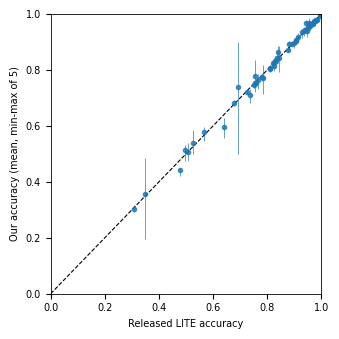

runs found: 20 (expect 20)


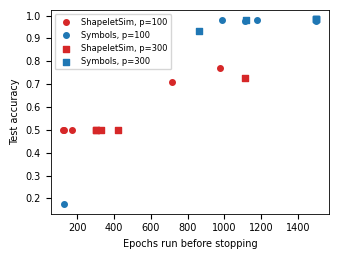

In [5]:
import glob, json, os
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 7, "axes.linewidth": 0.6})
ST = "/content/results_store"

# Figure 4: ours vs the released accuracy
paper = pd.read_csv("/content/LITE_src/results.csv")[["dataset", "LITE"]]
runs = pd.concat([pd.read_csv(f"{ST}/results_pass{i}/LITE/results_ucr.csv")[["dataset", "LITE-mean"]] for i in range(1, 6)])
g = runs.groupby("dataset")["LITE-mean"]
d = pd.DataFrame({"mine": g.mean(), "lo": g.min(), "hi": g.max()}).reset_index().merge(paper, on="dataset")
fig, ax = plt.subplots(figsize=(3.4, 3.4))
ax.errorbar(d["LITE"], d["mine"], yerr=[d["mine"] - d["lo"], d["hi"] - d["mine"]], fmt="o", ms=3, lw=0.6, alpha=0.8)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Released LITE accuracy"); ax.set_ylabel("Our accuracy (mean, min-max of 5)")
fig.tight_layout(); fig.savefig("/content/fig_repro.pdf"); plt.show()

# Figure 5: the 20 repeated runs, epochs vs accuracy
rows = []
for arm in ("C_es", "D_es_p300"):
    for k in range(5):
        for ds in ("Symbols", "ShapeletSim"):
            f = f"{ST}/results_{arm}_rep/seed{k}/LITE/results_ucr.csv"
            j = glob.glob(f"{ST}/results_{arm}_rep/seed{k}/LITE/run_0/{ds}/dict_emissions.json")
            if os.path.exists(f) and j:
                c = pd.read_csv(f); c = c[c["dataset"] == ds]
                rows.append(dict(arm=arm, ds=ds, acc=float(c["LITE-mean"].iloc[0]), ep=json.load(open(j[0]))["epochs_run"]))
r = pd.DataFrame(rows)
print("runs found:", len(r), "(expect 20)")
col = {"Symbols": "tab:blue", "ShapeletSim": "tab:red"}; mk = {"C_es": "o", "D_es_p300": "s"}
fig, ax = plt.subplots(figsize=(3.4, 2.6))
for (arm, ds), s in r.groupby(["arm", "ds"]):
    ax.scatter(s["ep"], s["acc"], c=col[ds], marker=mk[arm], s=16, label=f"{ds}, {'p=100' if arm == 'C_es' else 'p=300'}")
ax.set_xlabel("Epochs run before stopping"); ax.set_ylabel("Test accuracy"); ax.legend(fontsize=6)
fig.tight_layout(); fig.savefig("/content/fig_collapse.pdf"); plt.show()

In [6]:
from google.colab import files
import os
for f in ["fig_repro", "fig_collapse", "fig_totals", "fig_tradeoff", "fig_epochs"]:
    p = f"/content/{f}.pdf"
    if os.path.exists(p):
        files.download(p)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import glob, json, os
import pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
ST = "/content/results_store"
paper = pd.read_csv("/content/LITE_src/results.csv")[["dataset", "LITE"]]
runs = pd.concat([pd.read_csv(f"{ST}/results_pass{i}/LITE/results_ucr.csv")[["dataset", "LITE-mean"]] for i in range(1, 6)])
g = runs.groupby("dataset")["LITE-mean"]
d = pd.DataFrame({"mine": g.mean(), "lo": g.min(), "hi": g.max()}).reset_index().merge(paper, on="dataset")
fig, ax = plt.subplots(figsize=(3.4, 3.4))
ax.errorbar(d["LITE"], d["mine"], yerr=[d["mine"] - d["lo"], d["hi"] - d["mine"]], fmt="o", ms=3, lw=0.6, alpha=0.8)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Released LITE accuracy"); ax.set_ylabel("Our accuracy (mean, min-max of 5)")
fig.tight_layout(); fig.savefig("/content/fig_repro.pdf")

rows = []
for arm in ("C_es", "D_es_p300"):
    for k in range(5):
        for ds in ("Symbols", "ShapeletSim"):
            f = f"{ST}/results_{arm}_rep/seed{k}/LITE/results_ucr.csv"
            j = glob.glob(f"{ST}/results_{arm}_rep/seed{k}/LITE/run_0/{ds}/dict_emissions.json")
            if os.path.exists(f) and j:
                c = pd.read_csv(f); c = c[c["dataset"] == ds]
                rows.append(dict(arm=arm, ds=ds, acc=float(c["LITE-mean"].iloc[0]), ep=json.load(open(j[0]))["epochs_run"]))
r = pd.DataFrame(rows)
col = {"Symbols": "tab:blue", "ShapeletSim": "tab:red"}; mk = {"C_es": "o", "D_es_p300": "s"}
fig, ax = plt.subplots(figsize=(3.4, 2.6))
for (arm, ds), s in r.groupby(["arm", "ds"]):
    ax.scatter(s["ep"], s["acc"], c=col[ds], marker=mk[arm], s=16, label=f"{ds}, {'p=100' if arm == 'C_es' else 'p=300'}")
ax.set_xlabel("Epochs run before stopping"); ax.set_ylabel("Test accuracy"); ax.legend(fontsize=6)
fig.tight_layout(); fig.savefig("/content/fig_collapse.pdf")
print("saved")

saved


In [3]:
import pandas as pd
from scipy.stats import wilcoxon
ST = "/content/results_store"
ARMS = {"Original": "A_base", "Control": "B_split", "ES100": "C_es", "ES300": "D_es_p300"}
acc = pd.DataFrame({k: pd.read_csv(f"{ST}/results_{v}/LITE/results_ucr.csv").set_index("dataset")["LITE-mean"]
                    for k, v in ARMS.items()})
for a, b in (("ES100", "Original"), ("ES300", "Original"), ("ES100", "Control"), ("ES300", "Control")):
    d = acc[a] - acc[b]
    w, t, l = int((d > 0).sum()), int((d == 0).sum()), int((d < 0).sum())
    p = wilcoxon(d).pvalue if (d != 0).any() else float("nan")
    print(f"{a} vs {b}: wins/ties/losses = {w}/{t}/{l}, Wilcoxon p = {p:.3f}")

ES100 vs Original: wins/ties/losses = 3/2/5, Wilcoxon p = 0.250
ES300 vs Original: wins/ties/losses = 2/3/5, Wilcoxon p = 0.219
ES100 vs Control: wins/ties/losses = 1/3/6, Wilcoxon p = 0.031
ES300 vs Control: wins/ties/losses = 2/2/6, Wilcoxon p = 0.109
